# Practical 10 — Support Vector Machine (SVM) Classification

**Aim:** Classify breast tumours with an SVM, compare kernels, tune hyper-parameters and evaluate with train/test split and
k-fold CV (Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1, AUC).

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI, bundled with scikit-learn.

**Idea:** An SVM finds the separating hyperplane with the **maximum margin** (widest street between the classes).
Only the points on or inside the margin – the **support vectors** – define it.
* **C** – penalty for margin violations: small C = wide, tolerant margin; large C = strict, may over-fit.
* **Kernel trick** – implicitly maps the data to a higher-dimensional space so non-linear boundaries become possible
  (RBF kernel: K(x, x′) = exp(−γ‖x − x′‖²)). **γ** controls how local the influence of a single point is.
* Decision rule: sign of f(x) = Σᵢ αᵢ yᵢ K(xᵢ, x) + b, summed over support vectors only. SVMs need **scaled** features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all classification practicals)
The syllabus asks us to report **Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1-score and AUC**.
* `classification_metrics` – builds the confusion matrix `[[TN, FP], [FN, TP]]` and derives every metric from it
  (formulas are in the docstring).
* `kfold_evaluate` – manual **stratified k-fold cross-validation**: for every fold it clones the model, trains on
  k-1 folds, tests on the held-out fold and records all metrics, so you can see each intermediate result.

In [2]:
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import StratifiedKFold


def classification_metrics(y_true, y_pred, y_score=None):
    """Return all metrics required by the syllabus for a BINARY problem (positive class = 1).

    Accuracy    = (TP+TN)/(TP+TN+FP+FN)      Error       = 1 - Accuracy
    Recall      = TP/(TP+FN)  (sensitivity)  Specificity = TN/(TN+FP)
    Precision   = TP/(TP+FP)                 F1          = 2*P*R/(P+R)
    AUC         = area under the ROC curve (needs a continuous score, not the hard label)
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return pd.Series({"TP": tp, "TN": tn, "FP": fp, "FN": fn, "Accuracy": accuracy,
                      "Error": 1 - accuracy, "Recall": recall, "Specificity": specificity,
                      "Precision": precision, "F1": f1, "AUC": auc})


def get_score(model, X):
    """Continuous score used for AUC: P(class=1) if available, otherwise the SVM-style decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def kfold_evaluate(model, X, y, k=5, seed=42):
    """Stratified k-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = classification_metrics(y[te], m.predict(X[te]), get_score(m, X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        print(f"Fold {fold}: train={len(tr)}, test={len(te)}, accuracy={r['Accuracy']:.4f}, AUC={r['AUC']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})


def plot_cm_roc(model, X_test, y_test, title=""):
    """Confusion matrix + ROC curve side by side."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax[0], cmap="Blues",
                                          display_labels=["Benign (0)", "Malignant (1)"])
    ax[0].set_title(f"Confusion matrix {title}")
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, get_score(model, X_test)):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
    ax[1].set(xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)",
              title=f"ROC curve {title}")
    ax[1].legend(); plt.tight_layout(); plt.show()

## Step 1 — Load and inspect the data

In [3]:
data = load_breast_cancer(as_frame=True)
X_df = data.data                                  # 30 numeric features
y_s = (data.target == 0).astype(int)              # flip so that 1 = MALIGNANT (the "positive" class), 0 = benign
df = X_df.assign(target=y_s)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("\nClass balance (1 = malignant):")
print(y_s.value_counts().rename({0: "benign", 1: "malignant"}))
df.head()

Shape: (569, 31)
Missing values: 0

Class balance (1 = malignant):
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,1
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,1
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,1
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,1
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,1


## Step 2 — Split and scale

In [4]:
X, y = X_df.values, y_s.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", Xs_train.shape, "Test:", Xs_test.shape)

Train: (455, 30) Test: (114, 30)


## Step 3 — Linear SVM: what `fit()` produced, and how `decision_function` works
After training, a linear SVM is described by a weight vector **w** and bias **b**:
* `decision_function(x) = w·x + b` – signed (scaled) distance to the hyperplane
* predicted class = 1 if the value > 0, else 0
* the margin width is 2/‖w‖
* `support_vectors_` are the training points that lie on/inside the margin

In [5]:
lin = SVC(kernel="linear", C=1.0).fit(Xs_train, y_train)
w, b = lin.coef_[0], lin.intercept_[0]
print("Number of support vectors per class [benign, malignant]:", lin.n_support_,
      f"({lin.n_support_.sum()} of {len(y_train)} training points)")
print(f"‖w‖ = {np.linalg.norm(w):.4f}  →  margin width = 2/‖w‖ = {2 / np.linalg.norm(w):.4f}")

x0 = Xs_test[0]
f_manual = x0 @ w + b
print(f"\nSample 0:  w·x + b = {f_manual:.4f}  →  predicted class {int(f_manual > 0)}   (true: {y_test[0]})")
print(f"sklearn decision_function = {lin.decision_function(x0.reshape(1, -1))[0]:.4f},  predict = {lin.predict(x0.reshape(1, -1))[0]}")
print("All test decisions identical:", np.allclose(Xs_test @ w + b, lin.decision_function(Xs_test)))

Number of support vectors per class [benign, malignant]: [19 19] (38 of 455 training points)
‖w‖ = 2.7177  →  margin width = 2/‖w‖ = 0.7359

Sample 0:  w·x + b = -4.6160  →  predicted class 0   (true: 0)
sklearn decision_function = -4.6160,  predict = 0
All test decisions identical: True


## Step 4 — Compare kernels (default C = 1, γ = "scale")
`linear`: straight hyperplane · `poly`: polynomial curves · `rbf`: smooth flexible blobs · `sigmoid`: tanh-like (rarely best).

In [6]:
rows = {}
for kern in ["linear", "poly", "rbf", "sigmoid"]:
    m = SVC(kernel=kern, random_state=42).fit(Xs_train, y_train)
    r = classification_metrics(y_test, m.predict(Xs_test), m.decision_function(Xs_test))
    rows[kern] = {"n_support_vectors": m.n_support_.sum(), "train_acc": m.score(Xs_train, y_train),
                  "Accuracy": r["Accuracy"], "Recall": r["Recall"], "Specificity": r["Specificity"], "F1": r["F1"], "AUC": r["AUC"]}
display(pd.DataFrame(rows).T.round(4))

,n_support_vectors,train_acc,Accuracy,Recall,Specificity,F1,AUC
linear,38.0,0.9890,0.9649,0.9048,1.0000,0.9500,0.9914
poly,149.0,0.9121,0.8860,0.6905,1.0000,0.8169,0.9967
rbf,107.0,0.9868,0.9737,0.9286,1.0000,0.9630,0.9947
sigmoid,70.0,0.9495,0.9474,0.8810,0.9861,0.9250,0.9954


## Step 5 — Visualising the margin and support vectors in 2-D
The data has 30 dimensions, so we project it to 2 principal components (PCA) purely for a picture and refit the SVM there.
Solid line = decision boundary (f = 0), dashed lines = margins (f = ±1), circled points = support vectors.

Variance kept by the 2 components: 63.1 %


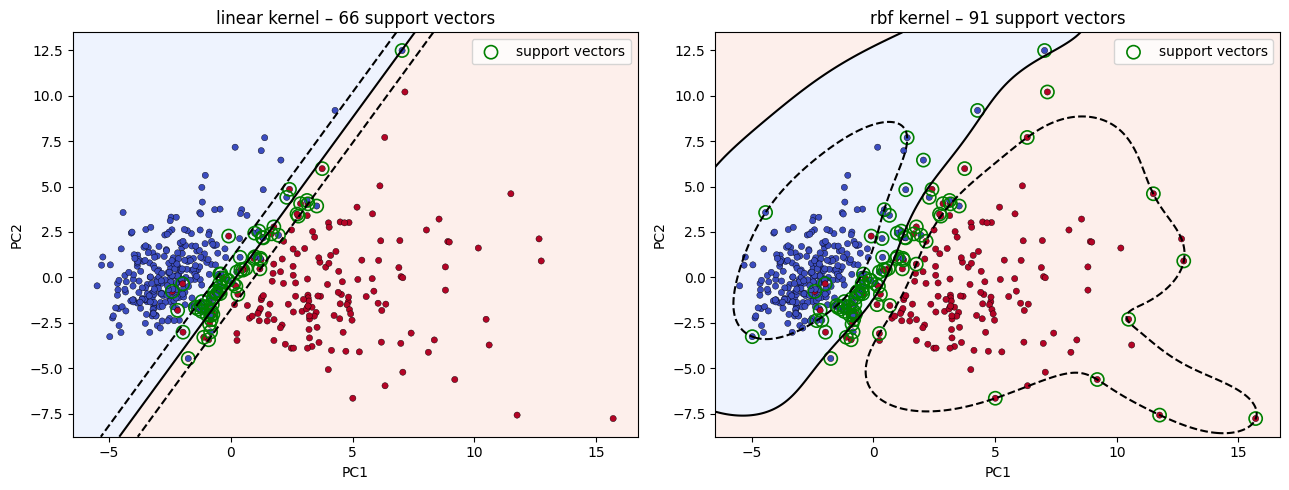

In [7]:
pca = PCA(n_components=2).fit(Xs_train)
P_train = pca.transform(Xs_train)
print("Variance kept by the 2 components: %.1f %%" % (100 * pca.explained_variance_ratio_.sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
xx, yy = np.meshgrid(np.linspace(P_train[:, 0].min() - 1, P_train[:, 0].max() + 1, 300),
                     np.linspace(P_train[:, 1].min() - 1, P_train[:, 1].max() + 1, 300))
for ax, (kern, C) in zip(axes, [("linear", 1.0), ("rbf", 1.0)]):
    m = SVC(kernel=kern, C=C).fit(P_train, y_train)
    Z = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap="coolwarm")
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(P_train[:, 0], P_train[:, 1], c=y_train, cmap="coolwarm", edgecolor="k", linewidth=0.3, s=20)
    ax.scatter(*m.support_vectors_.T, s=90, facecolors="none", edgecolors="green", linewidths=1.2, label="support vectors")
    ax.set_title(f"{kern} kernel – {len(m.support_vectors_)} support vectors"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
plt.tight_layout(); plt.show()

## Step 6 — Hyper-parameter tuning with `GridSearchCV`
For every (C, γ) pair in the grid GridSearchCV runs 5-fold CV **inside the training set** and records the mean accuracy.
It finally refits the best pair on the whole training set. The test set is not used for tuning.

Combinations tried: 16 × 5 folds = 80 fits
Best parameters   : {'svc__C': 10, 'svc__gamma': 0.01}
Best CV accuracy  : 0.9758


,γ=0.001,γ=0.01,γ=0.1,γ=1
C=0.1,0.7165,0.9451,0.9319,0.6264
C=1,0.9495,0.9648,0.9582,0.6308
C=10,0.9648,0.9758,0.9582,0.6374
C=100,0.9736,0.9692,0.9560,0.6374


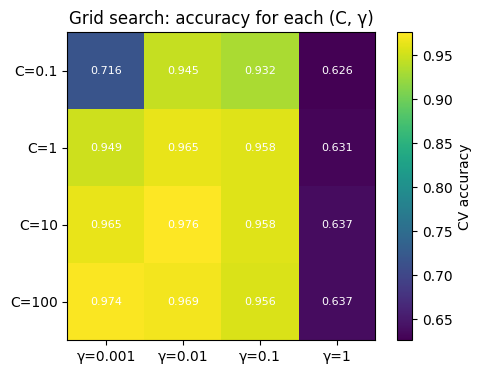

In [8]:
param_grid = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]}
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grid = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="accuracy")
grid.fit(X_train, y_train)

print("Combinations tried:", len(grid.cv_results_["params"]), "× 5 folds =", len(grid.cv_results_["params"]) * 5, "fits")
print("Best parameters   :", grid.best_params_)
print("Best CV accuracy  : %.4f" % grid.best_score_)

heat = pd.DataFrame(grid.cv_results_["mean_test_score"].reshape(4, 4),
                    index=[f"C={c}" for c in param_grid["svc__C"]], columns=[f"γ={g}" for g in param_grid["svc__gamma"]])
display(heat.round(4))
plt.figure(figsize=(5.5, 4)); plt.imshow(heat.values, cmap="viridis"); plt.colorbar(label="CV accuracy")
plt.xticks(range(4), heat.columns); plt.yticks(range(4), heat.index)
for i in range(4):
    for j in range(4): plt.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
plt.title("Grid search: accuracy for each (C, γ)"); plt.show()

## Step 7 — Evaluation of the tuned model on the hold-out test set

TP             40.0000
TN             72.0000
FP              0.0000
FN              2.0000
Accuracy        0.9825
Error           0.0175
Recall          0.9524
Specificity     1.0000
Precision       1.0000
F1              0.9756
AUC             0.9960

              precision    recall  f1-score   support

      benign       0.97      1.00      0.99        72
   malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



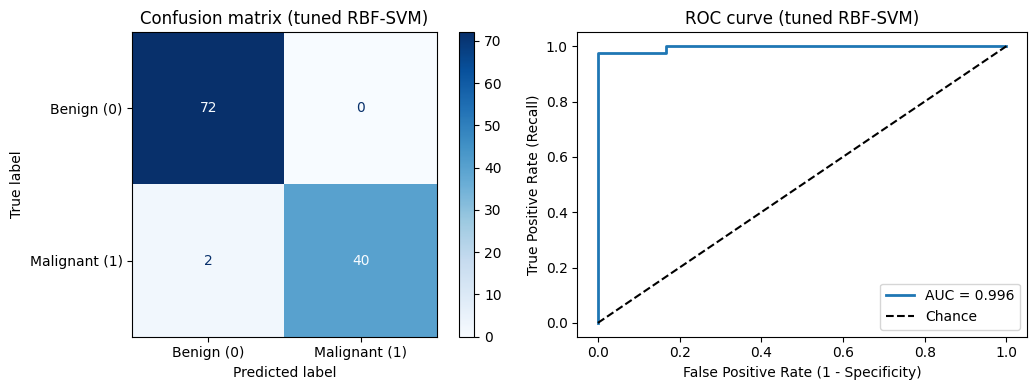

In [9]:
best_model = grid.best_estimator_                       # scaler + tuned SVC (trained on all training data)
y_pred = best_model.predict(X_test)
test_m = classification_metrics(y_test, y_pred, best_model.decision_function(X_test))
print(test_m.round(4).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"]))
plot_cm_roc(best_model, X_test, y_test, title="(tuned RBF-SVM)")

## Step 8 — k-fold cross-validation (k = 5) of the tuned model

In [10]:
best_C, best_gamma = grid.best_params_["svc__C"], grid.best_params_["svc__gamma"]
final_pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=best_C, gamma=best_gamma))
folds, summary = kfold_evaluate(final_pipe, X, y, k=5)
print()
display(folds.round(4)); display(summary.round(4))

Fold 1: train=455, test=114, accuracy=1.0000, AUC=1.0000
Fold 2: train=455, test=114, accuracy=0.9474, AUC=0.9941
Fold 3: train=455, test=114, accuracy=0.9825, AUC=0.9864
Fold 4: train=455, test=114, accuracy=0.9912, AUC=1.0000
Fold 5: train=456, test=113, accuracy=0.9823, AUC=0.9993



,TP,TN,FP,FN,Accuracy,Error,Recall,Specificity,Precision,F1,AUC
Fold 1,43.0,71.0,0.0,0.0,1.0000,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Fold 2,39.0,69.0,2.0,4.0,0.9474,0.0526,0.9070,0.9718,0.9512,0.9286,0.9941
Fold 3,40.0,72.0,0.0,2.0,0.9825,0.0175,0.9524,1.0000,1.0000,0.9756,0.9864
Fold 4,42.0,71.0,1.0,0.0,0.9912,0.0088,1.0000,0.9861,0.9767,0.9882,1.0000
Fold 5,40.0,71.0,0.0,2.0,0.9823,0.0177,0.9524,1.0000,1.0000,0.9756,0.9993


,mean,std
TP,40.8000,1.6432
TN,70.8000,1.0954
FP,0.6000,0.8944
FN,1.6000,1.6733
Accuracy,0.9807,0.0200
Error,0.0193,0.0200
Recall,0.9623,0.0391
Specificity,0.9916,0.0126
Precision,0.9856,0.0217
F1,0.9736,0.0271


## Step 9 — Summary

In [11]:
display(pd.DataFrame({"Hold-out test": test_m, "5-fold CV mean": summary["mean"]}).round(4))

,Hold-out test,5-fold CV mean
TP,40.0000,40.8000
TN,72.0000,70.8000
FP,0.0000,0.6000
FN,2.0000,1.6000
Accuracy,0.9825,0.9807
Error,0.0175,0.0193
Recall,0.9524,0.9623
Specificity,1.0000,0.9916
Precision,1.0000,0.9856
F1,0.9756,0.9736


### Conclusion
* A linear SVM is a hyperplane `w·x + b = 0`; the manual `w·x + b` reproduces `decision_function`, and only the support vectors (a subset of the training data) determine it.
* RBF/linear kernels both work well on this almost linearly separable data; the RBF kernel gains flexibility but needs careful C and γ (grid search).
* Large γ or very large C over-fits (many tiny islands); small values under-fit – the heat-map shows the sweet spot.
* Scaling is essential; the pipeline guarantees the scaler is fitted only on training data in every fold.